# Random microsphere scattering medium — volumetric speckle
A plane wave enters a slab of randomly packed dielectric microspheres (n ≈ 1.33,
a water-like index with a touch of absorption) suspended in air. After only a few
layers the smooth incident wavefront has shattered into a fully three-dimensional
**speckle** field: the coherent sum of light scattered off thousands of spheres
along every possible path. Disordered-medium scattering of this kind is the
canonical problem the convergent/modified Born series (MBS) was developed for
(Osnabrugge, Leedumrongwatthanakun & Vellekoop, J. Comput. Phys. 322, 2016).

Why a full-wave solver is required (and ray tracing is not enough)
------------------------------------------------------------------
Speckle is pure multiple *coherent* scattering: it is the interference of
millions of scattered partial waves. There is no ray-optics picture of a speckle
grain — it exists only because the field has a phase and that phase adds up
coherently over many scattering events. A ray tracer models each sphere as a
refracting/reflecting surface and produces a smooth blur; it has no mechanism to
produce the high-contrast granular field you actually measure.

Physics / solver mode
---------------------
Scalar Helmholtz (one CW frequency, linear, non-magnetic). The scalar model — not
vector Maxwell — is the standard description of disordered-medium scattering and
carries one field component instead of three. The output is the steady-state
complex field; |field|² is the speckle intensity.

Geometry (propagation = X; transverse = Y, Z)
---------------------------------------------
  * A cube domain. A slab spanning x ∈ [x_slab0, x_slab1] is packed with randomly
    placed, non-overlapping dielectric microspheres (radius ``sphere_radius``,
    index ``sphere_index`` ≈ 1.33 + small absorption) in an air background; air
    gaps before and after the slab let the speckle radiate out the far side.
  * Spheres are placed by random sequential addition with overlap rejection up to
    a target fill fraction, then rasterized into a per-voxel permittivity (n²)
    grid. The achieved fill fraction is reported (RSA jams below the target).
  * Open (absorbing) boundaries on all six faces; the apodized plane-wave source
    is tapered (Tukey window) in Y and Z so there is no hard-aperture diffraction
    off the domain edges.

Everything that sets the scene — wavelength, domain size, grid spacing, slab
extent, sphere radius/index, fill fraction — is a top-level variable so the
example re-scales. Defaults resolve each sphere with ~12 voxels across (~5 Mvoxel
without boundaries); raise ``sim_size`` / ``fill_fraction`` for a larger slab.

Size: 16.59 Mvoxel including boundaries, 0.371 GB of memory (service estimate).

Outputs (saved in output/<NAME>/ at the repo root)
--------------------------------------------------
  * microspheres_xy_slice.png  — an X–Y cut through the volume: the plane
    wave enters clean (left) and breaks into volumetric speckle inside the slab;
  * microspheres_transverse.png — Y–Z transverse cut-planes at increasing
    depth, showing the speckle building up through the slab and the transmitted
    speckle pattern on the far side;
  * microspheres_volume.npy    — a downsampled |field| volume for 3-D
    rendering, plus microspheres_index.npy (downsampled index map).

The sphere packing + rasterization is built directly with NumPy.

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wsutils import apodise, output_dir
from wavesimpro import configure, simulate

NAME = "hmhz_random_microspheres"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

### Parameters

In [2]:
wavelength = 1.0  # Wavelength in micrometer (μm), in the air background (n = 1)
pixel_size = wavelength / 8  # Grid spacing in μm. ~8 px/λ in air, ~6 px/λ inside the
#                              n=1.33 spheres -> each sphere is ~12 voxels across, so the
#                              curved surface is well resolved rather than staircased.
#                              Use λ/5 for a coarser grid, λ/10 for a finer one.

# Domain: a cube. X = propagation, Y, Z = transverse. Scale sim_size up (and
# fill_fraction toward ~0.35) for a larger slab.
sim_size = np.array([26.0, 20.0, 20.0])  # (x, y, z) simulation size in μm
n_size = (sim_size / pixel_size).astype(int)
nx, ny, nz = (int(v) for v in n_size)

# Scattering slab: fills part of the domain in X, leaving air gaps either side.
x_slab0 = 4.0  # front face of the slab, μm
x_slab1 = 22.0  # back face of the slab, μm
slab_thickness = x_slab1 - x_slab0  # μm

# Microspheres.
sphere_radius = 0.75  # sphere radius, μm (size parameter 2πr/λ ≈ 4.7 — Mie regime)
sphere_index = 1.33 + 0.002j  # n ≈ water-like, with a small absorption (positive imag)
bg_index = 1.0  # air background
fill_fraction = 0.25  # target volume fraction of spheres in the slab (RSA jams below this)
seed = 0  # RNG seed for reproducible packing

# Source: apodized normal-incidence plane wave, launched just inside the front gap.
x_src = 1.5  # μm (after the absorbing boundary, before the slab)
taper = 0.35  # Tukey taper fraction in Y and Z (kills hard-aperture diffraction)

# Output volume downsampling (for 3-D rendering; the full volume can be large).
vol_downsample = 2

print(f"Domain {sim_size} μm = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.2f} Mvoxel without boundaries)")
print(f"Slab x = {x_slab0}–{x_slab1} μm  (thickness {slab_thickness:.0f} μm = "
      f"{slab_thickness / wavelength:.0f} λ)")
print(f"Spheres: r = {sphere_radius} μm (size param 2πr/λ = {2 * np.pi * sphere_radius / wavelength:.2f}), "
      f"n = {sphere_index}, Δn = {sphere_index.real - bg_index:.2f}")

Domain [26. 20. 20.] μm = 208x160x160 voxels (5.32 Mvoxel without boundaries)
Slab x = 4.0–22.0 μm  (thickness 18 μm = 18 λ)
Spheres: r = 0.75 μm (size param 2πr/λ = 4.71), n = (1.33+0.002j), Δn = 0.33


### Medium: random sphere packing -> per-voxel permittivity

In [3]:
def pack_spheres():
    """Random sequential addition of non-overlapping spheres into the slab.

    Returns the list of (x, y, z) centres (μm). Stops at the target fill fraction
    or when the attempt budget is exhausted (RSA saturates well below close
    packing), so the *achieved* fill fraction is reported, not assumed.
    """
    rng = np.random.default_rng(seed)
    r = sphere_radius
    # Keep centres a radius inside the slab in X and inside the domain in Y, Z so
    # every sphere lies fully within the simulated (physical) grid.
    lo = np.array([x_slab0 + r, r, r])
    hi = np.array([x_slab1 - r, sim_size[1] - r, sim_size[2] - r])

    slab_volume = slab_thickness * sim_size[1] * sim_size[2]
    sphere_volume = 4.0 / 3.0 * np.pi * r**3
    target_count = int(fill_fraction * slab_volume / sphere_volume)
    max_attempts = 50 * target_count  # generous budget; RSA jams before this

    centers = np.empty((0, 3))
    min_dist2 = (2 * r) ** 2  # squared centre-to-centre distance for non-overlap
    attempts = 0
    while len(centers) < target_count and attempts < max_attempts:
        attempts += 1
        c = lo + rng.random(3) * (hi - lo)
        if len(centers) == 0 or np.all(((centers - c) ** 2).sum(axis=1) >= min_dist2):
            centers = np.vstack([centers, c])

    achieved = len(centers) * sphere_volume / slab_volume
    print(f"Packed {len(centers)} spheres in {attempts} attempts "
          f"(target {target_count}); achieved fill fraction {achieved:.3f} "
          f"(requested {fill_fraction:.3f})")
    return centers


def build_permittivity(centers):
    """Rasterize the packed spheres into an (nx, ny, nz) permittivity (n²) grid.

    Each sphere is painted only inside its local bounding box (not the whole
    array).
    """
    n = np.full((nx, ny, nz), bg_index, dtype=np.complex64)
    x = np.arange(nx) * pixel_size
    y = np.arange(ny) * pixel_size
    z = np.arange(nz) * pixel_size
    r = sphere_radius
    r2 = r**2
    for cx, cy, cz in centers:
        # Bounding-box voxel index range for this sphere.
        ix0, ix1 = int((cx - r) / pixel_size), int((cx + r) / pixel_size) + 1
        iy0, iy1 = int((cy - r) / pixel_size), int((cy + r) / pixel_size) + 1
        iz0, iz1 = int((cz - r) / pixel_size), int((cz + r) / pixel_size) + 1
        ix0, iy0, iz0 = max(ix0, 0), max(iy0, 0), max(iz0, 0)
        ix1, iy1, iz1 = min(ix1, nx), min(iy1, ny), min(iz1, nz)
        if ix0 >= ix1 or iy0 >= iy1 or iz0 >= iz1:
            continue
        dx = (x[ix0:ix1] - cx)[:, None, None]
        dy = (y[iy0:iy1] - cy)[None, :, None]
        dz = (z[iz0:iz1] - cz)[None, None, :]
        inside = dx**2 + dy**2 + dz**2 < r2
        block = n[ix0:ix1, iy0:iy1, iz0:iz1]
        block[inside] = sphere_index
        n[ix0:ix1, iy0:iy1, iz0:iz1] = block
    return (n**2).astype(np.complex64)


centers = pack_spheres()
permittivity = build_permittivity(centers)

Packed 1018 spheres in 13501 attempts (target 1018); achieved fill fraction 0.250 (requested 0.250)


### Source: apodized normal-incidence plane wave (scalar Helmholtz)

In [4]:
# A single-x-thick sheet spanning Y, Z, tapered to zero at the edges so the
# illumination does not diffract off the domain boundary. Constant phase across
# the sheet -> a plane wave propagating in +x.
source_values = np.ones((1, ny, nz), dtype=np.complex64)
source_position = [int(x_src / pixel_size), 0, 0]  # scalar: (x, y, z) in pixels
source_values, source_position = apodise((source_values, source_position),
                                         axes="yz", alpha=taper)

### Solve

In [5]:
print("\nRunning simulation...")
start = time()
u, iterations, residual_norm = simulate(
    permittivity=permittivity,
    sources=[(source_values, source_position)],
    wavelength=wavelength,
    pixel_size=pixel_size,
    boundary_width=5.0,  # absorbing boundary width, μm (5 λ), open on all six faces
    periodic=(False, False, False),
)
print(f"Time {time() - start:.1f} s; Iterations {iterations}; Residual {residual_norm:.2e}")

u = np.asarray(u)  # scalar field, (nx, ny, nz), host NumPy
amp = np.abs(u)


Running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 775666bd-032e-4c69-8119-4e84cb3a1ff4
  Version   : a822f0de-1ded-44bf-a6f4-a7b714f62a55
  Command   : 88fd7468-24a2-44b5-a8a4-d12b2e2a57ff
  Mode      : Helmholtz (scalar)
  Domain    : 208x160x160 voxels  lambda=1.0 um  dx=0.125 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 50.5 s; Iterations 465; Residual 9.93e-07


### Save downsampled volume + index map for 3-D rendering

In [6]:
ds = vol_downsample
np.save(f"{OUTPUT_DIR}/microspheres_volume.npy", amp[::ds, ::ds, ::ds].astype(np.float32))
np.save(f"{OUTPUT_DIR}/microspheres_index.npy",
        np.sqrt(permittivity.real)[::ds, ::ds, ::ds].astype(np.float32))
print(f"Saved downsampled |field| + index volumes ({amp[::ds, ::ds, ::ds].shape}) to output/{NAME}/")

Saved downsampled |field| + index volumes ((104, 80, 80)) to output/hmhz_random_microspheres/


### Figure 1: X–Y cut through the volume (z = centre)

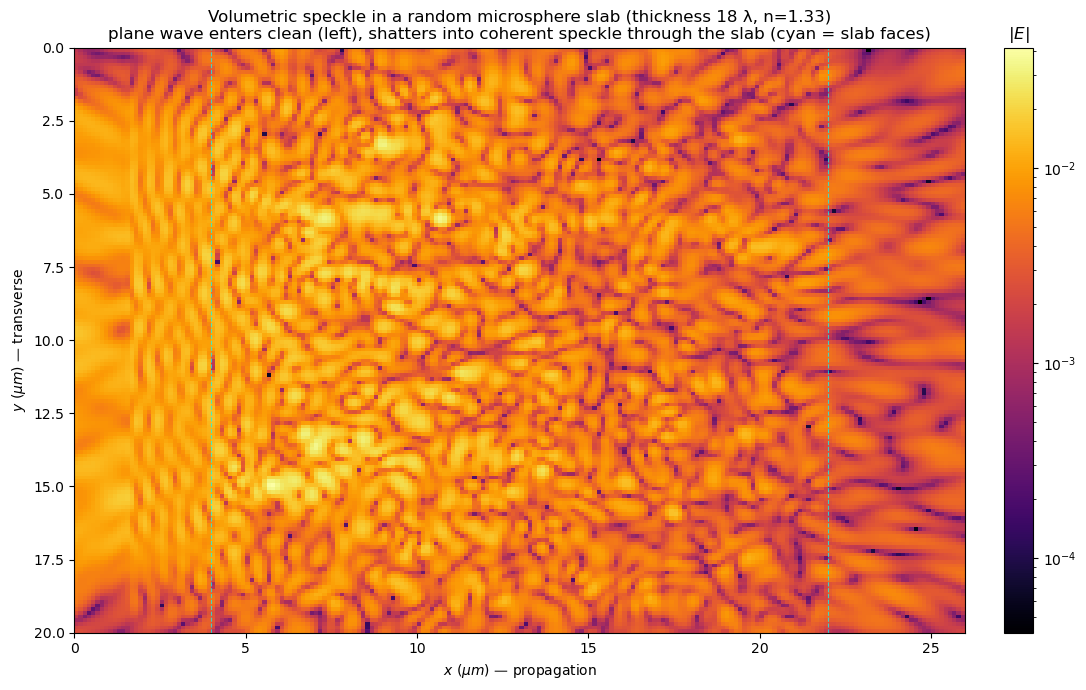

In [7]:
# Plane wave enters clean on the left, shatters into speckle inside the slab.
sl = amp[:, :, nz // 2]
vmax = sl.max()
vmin = vmax * 1e-3
extent = [0, nx * pixel_size, ny * pixel_size, 0]  # x horizontal, y vertical (origin top)

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(sl.T, cmap="inferno", extent=extent,
               norm=colors.LogNorm(vmin=vmin, vmax=vmax), aspect="auto")
ax.axvline(x_slab0, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.axvline(x_slab1, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.set_xlabel(r"$x~(\mu m)$ — propagation")
ax.set_ylabel(r"$y~(\mu m)$ — transverse")
ax.set_title(f"Volumetric speckle in a random microsphere slab "
             f"(thickness {slab_thickness / wavelength:.0f} λ, n={sphere_index.real})\n"
             "plane wave enters clean (left), shatters into coherent speckle through the slab "
             "(cyan = slab faces)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/microspheres_xy_slice.png", dpi=300, bbox_inches="tight")

### Figure 2: transverse Y–Z speckle planes at increasing depth

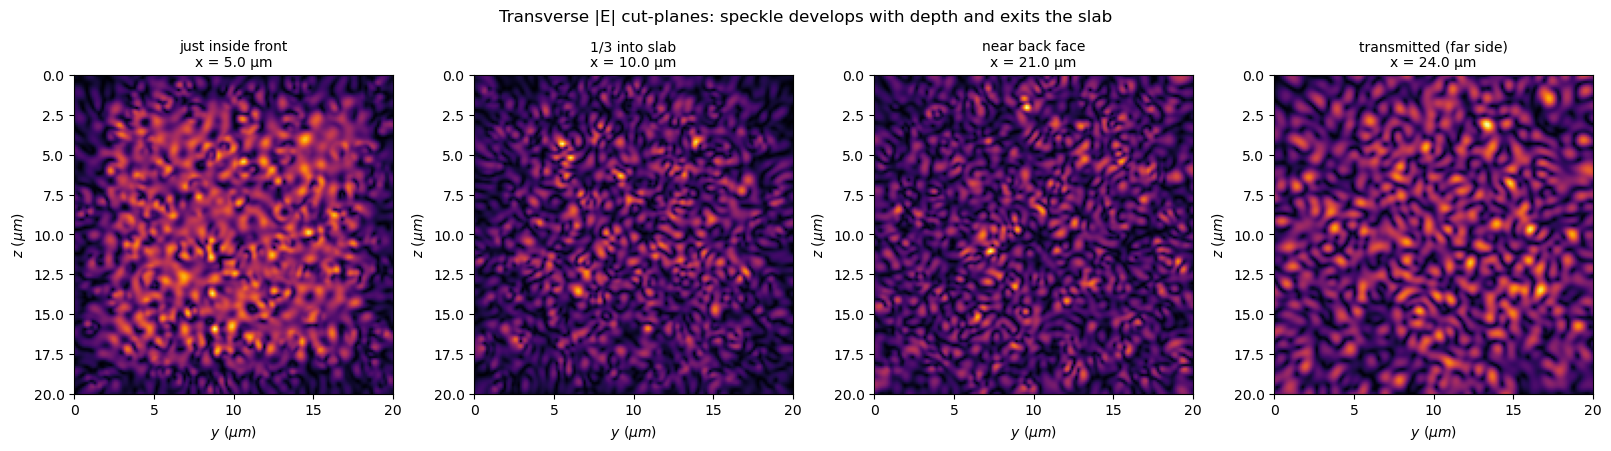

In [8]:
# Entrance, two depths inside the slab, and the transmitted far side.
x_planes = [x_slab0 + 1.0, x_slab0 + slab_thickness / 3, x_slab1 - 1.0,
            min(x_slab1 + 2.0, (nx - 1) * pixel_size)]
labels = ["just inside front", "1/3 into slab", "near back face", "transmitted (far side)"]
extent_t = [0, ny * pixel_size, nz * pixel_size, 0]

fig2, axes = plt.subplots(1, 4, figsize=(16, 4.4), constrained_layout=True)
for ax, xp, lab in zip(axes, x_planes, labels):
    ix = int(xp / pixel_size)
    plane = amp[ix, :, :]
    ax.imshow(plane.T, cmap="inferno", extent=extent_t, aspect="equal")
    ax.set_title(f"{lab}\nx = {xp:.1f} μm", fontsize=10)
    ax.set_xlabel(r"$y~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$")
fig2.suptitle("Transverse |E| cut-planes: speckle develops with depth and exits the slab",
              fontsize=12)
fig2.savefig(f"{OUTPUT_DIR}/microspheres_transverse.png", dpi=300, bbox_inches="tight")

### Report scattering / speckle statistics

In [9]:
# Speckle intensity contrast C = std(I)/mean(I); C -> 1 for fully developed
# (Rayleigh) speckle. Measured on the transmitted far-side plane.
ix_far = int(min(x_slab1 + 2.0, (nx - 1) * pixel_size) / pixel_size)
intensity = amp[ix_far, :, :] ** 2
contrast = intensity.std() / intensity.mean()
print(f"\nTransmitted-plane speckle contrast C = std(I)/mean(I) = {contrast:.2f} "
      f"(C → 1 for fully developed speckle)")
print(f"Saved output/{NAME}/microspheres_xy_slice.png and output/{NAME}/microspheres_transverse.png")

plt.show()


Transmitted-plane speckle contrast C = std(I)/mean(I) = 1.00 (C → 1 for fully developed speckle)
Saved output/hmhz_random_microspheres/microspheres_xy_slice.png and output/hmhz_random_microspheres/microspheres_transverse.png
